In [2]:
# импортируем необходимые библиотеки

import pandas as pd
import numpy as np

In [3]:
# загружаем необходимые файлы

loginLogs = pd.read_csv("login_logs.csv")
salesOrdersItems = pd.read_csv("sales_orders_items.csv")
salesOrders = pd.read_csv("sales_orders.csv")

In [4]:
# преобразуем тип данных в столбце login_time таблицы loginLogs

loginLogs["login_time"] = pd.to_datetime(loginLogs["login_time"])

In [5]:
# создаем новые столбцы в loginLogs

loginLogs["year"] = [i.year for i in loginLogs["login_time"]]
loginLogs["month"] = [i.month for i in loginLogs["login_time"]]
loginLogs["day"] = [i.day for i in loginLogs["login_time"]]

# User Growth Rate = -13.362%

In [6]:
# создаем сводную таблицу, чтобы посчитать количество уникальных пользователей в каждый год

table_ugr = loginLogs.drop_duplicates(subset = ["user_id"]).groupby(by = ["year", "month"]).count()["user_id"].sort_values(ascending = False)

In [7]:
# рассчитываем и выводим User Growth Rate

ugr = ((table_ugr[2022, 7] - table_ugr[2021, 7]) / table_ugr[2021, 7]) * 100

print(f"User Growth Rate is {round(ugr, 3)}%")

User Growth Rate is -13.362%


# MAU визуализация

<Axes: xlabel='date'>

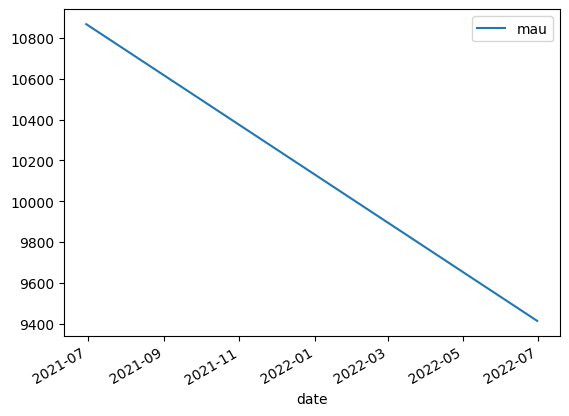

In [34]:
mau = pd.DataFrame({"date": [pd.Timestamp(year = 2021, month = 6, day = 30), pd.Timestamp(year = 2022, month = 6, day = 30)],
                   "mau": [table_ugr[2021, 7], table_ugr[2022, 7]]}).set_index(["date"])

mau.plot()

# Расчет Churn rate, Retention rate и DAU

In [49]:
# Создаем цикл для расчета Churn rate, Retention rate и DAU

churn_rates = []
retention_rates = []
dau_2021 = []
dau_2022 = []
td = pd.Timedelta(365, "d")

for day in range(1, 31):
    subset_by_day = loginLogs[(loginLogs["year"] == 2021) & (loginLogs["day"] == day)]
    

    ls_uniq_users = set(subset_by_day.drop_duplicates(subset = ["user_id"])["user_id"].values)
    
    subset_by_day_plus_td = loginLogs[(loginLogs["login_time"] > pd.Timestamp(year = 2021, month = 7, day = day)) & (loginLogs["login_time"] > (pd.Timestamp(year = 2021, month = 7, day = day) + td))]

    ls_uniq_users_plus_td = set(subset_by_day_plus_td.drop_duplicates(subset = ["user_id"])["user_id"].values)

    churn_rates.append((len(ls_uniq_users - ls_uniq_users_plus_td) / len(ls_uniq_users)) * 100)

    retention_rates.append((len(ls_uniq_users & ls_uniq_users_plus_td) / len(ls_uniq_users)) * 100)

    dau_2021.append(len(ls_uniq_users))

    subset_by_day_2022 = loginLogs[(loginLogs["year"] == 2022) & (loginLogs["day"] == day)]

    ls_uniq_users_2022 = set(subset_by_day_2022.drop_duplicates(subset = ["user_id"])["user_id"].values)

    dau_2022.append(len(ls_uniq_users_2022))

dau = dau_2021 + dau_2022


<Axes: xlabel='dates'>

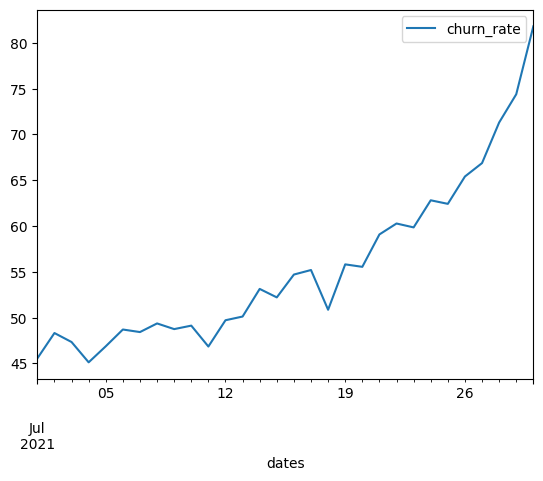

In [50]:
churn_retention_dates = []

for i in range(1, 31):
    churn_retention_dates.append(pd.Timestamp(year = 2021, month = 7, day = i))

churn = pd.DataFrame({"dates": churn_retention_dates, "churn_rate": churn_rates}).set_index(["dates"])

retention = pd.DataFrame({"dates": churn_retention_dates, "retention_rate": retention_rates}).set_index(["dates"])

churn.plot()

<Axes: xlabel='dates'>

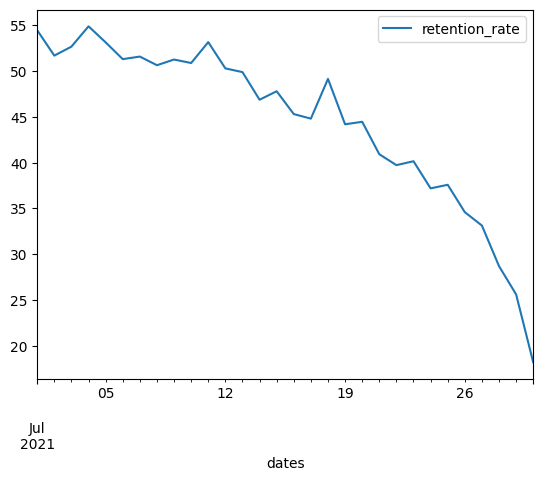

In [51]:
retention.plot()

<Axes: xlabel='dates'>

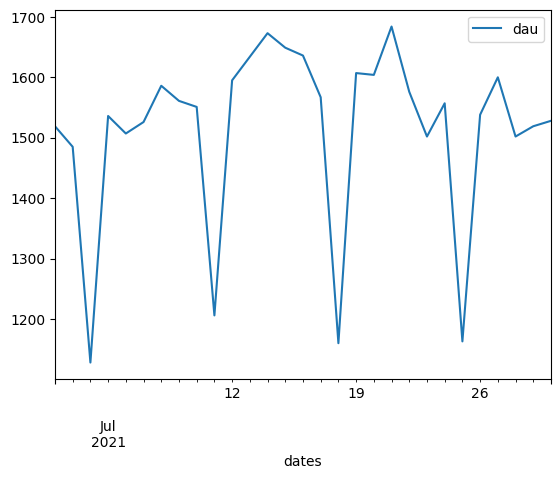

In [55]:
dau_dates = []

for i in range(1, 31):
    dau_dates.append(pd.Timestamp(year = 2021, month = 7, day = i))

for i in range(1, 31):
    dau_dates.append(pd.Timestamp(year = 2022, month = 7, day = i))

dau_plot = pd.DataFrame({"dates": dau_dates, "dau": dau}).set_index(["dates"])

dau_plot[1:30].plot()

<Axes: xlabel='dates'>

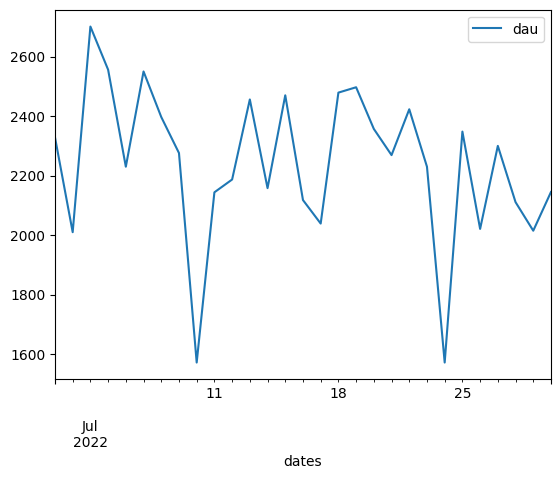

In [56]:
dau_plot[31:62].plot()

# Топ-10 самых популярных товаров

In [9]:
# Сводная таблица, чтобы показать топ-10 самых заказываемых товаров

salesOrdersItems.groupby(by = ["fk_product_id"]).count()["fk_order_id"].sort_values(ascending = False).head(10)

fk_product_id
10235    908
8444     822
1041     624
8425     590
3610     488
10975    469
1038     382
8219     362
10236    353
8210     337
Name: fk_order_id, dtype: int64

# Расчет дохода каждого товара

In [10]:
# Создаем столбец total, чтобы рассчитать выручку

salesOrdersItems["total"] = salesOrdersItems["ordered_quantity"] * salesOrdersItems["rate"]

In [11]:
# Сводная таблица для расчета доходности у каждого артикула

salesOrdersItems.groupby(by = ["fk_product_id"])["total"].sum().sort_values(ascending = False).head(10)

fk_product_id
8219     45077054.70
1043     25241563.74
8210     22118982.40
3610     16935587.00
8444     15233475.30
10975    13525929.79
12547    13071850.00
7640     12857219.60
7666     11593485.00
12652     8077240.60
Name: total, dtype: float64

# Расчет общей выручки

In [12]:
# Создаем новую таблицу из salesOrdersItems и salesOrders

sales = salesOrdersItems.merge(salesOrders, how = "inner", left_on = "fk_order_id", right_on = "order_id")

In [13]:
# Преобразуем тип данных в столбце creation_time

sales["creation_time"] = pd.to_datetime(sales["creation_time"])

In [14]:
# Создаем новые столбцы в таблице sales

sales["year"] = [i.year for i in sales["creation_time"]]
sales["month"] = [i.month for i in sales["creation_time"]]
sales["day"] = [i.day for i in sales["creation_time"]]

In [15]:
# Создаем сводную таблицу, чтобы узнать выручку за каждый год

sales.groupby(by = ["year"])["total"].sum()

year
2021    1.714556e+08
2022    2.302574e+08
Name: total, dtype: float64

# Статус заказа

In [57]:
# Сводная таблица с количеством заказов у каждого статуса заказа

sales.groupby(by = ["sales_order_status"])["fk_order_id"].count().sort_values(ascending = False)

sales_order_status
Rejected    11094
Shipped      9307
Pending        86
Review          1
Name: fk_order_id, dtype: int64

# Корреляция между частотой входа на сайт и количеством заказов

In [17]:
# Создаем общую таблица из двух сводных таблиц: первая -- количество заходов на сайт для каждого пользователя, вторая -- количество заказов для каждого польщователя

count_logs = loginLogs.groupby(by = ["user_id"])["login_log_id"].count().reset_index()

count_total = sales.groupby(by = ["fk_buyer_id"])["fk_order_id"].count().reset_index()

final = count_logs.merge(count_total, how = "inner", left_on = "user_id", right_on = "fk_buyer_id")

In [21]:
# Коэффициент корреляции Пирсона

final["login_log_id"].corr(final["fk_order_id"])

0.42575722526399123

In [22]:
# Коэффициент корреляции Спирмена

final["login_log_id"].corr(final["fk_order_id"], method = "spearman")

0.5569816393623416

In [23]:
# Коэффициент корреляции Кенделла

final["login_log_id"].corr(final["fk_order_id"], method = "kendall")

0.41964832612525393